# Flight delay classification — Support Vector Machine, tuned revision
**Ridhima Singhal**

Place this notebook alongside the original **Flight Dataset**, **Unknown Dataset** and **Kaggle Submission Sample** CSVs. Choose your Python kernel and click **Run All**. The final cell creates **`svm1.csv`** in the same folder as the Flight CSV. It creates no model output folder. This notebook is self-contained; no other notebook or custom `.py` file is required.

Normal execution uses the measured, frozen tuning result and then trains both the 80% evaluation model and the final submission model. `RUN_TUNING=True` repeats the three-fold comparison of shortlisted settings; `RUN_FULL_SEARCH=True` additionally repeats the initial parameter search. The default run can take several minutes. Full search takes substantially longer.

**Kaggle accuracy for this revision is not yet measured.** Accuracy and weighted F1 are reported separately. Tuning cannot guarantee a particular Kaggle score.

## Evaluation scope and safeguards
- Fixed stratified **80% training / 20% development holdout**, random seed 42.
- Feature construction, parameter selection and cutoff selection use the training 80% only. The initial search uses its first internal fold; the three strongest candidates then receive three-fold comparison. These are selection scores, not unbiased test estimates.
- Added missing values approximate the unknown file's unlabelled missingness rates. Masked-validation accuracy is the main selection measure; original-validation accuracy breaks ties.
- Route and historical target features are fitted within each split. Training features use five-fold cross-fitting on unique flights. The holdout is never used for early stopping or threshold selection. It was inspected during earlier development, so it is a development holdout rather than a new blind test.
- Boosting and neural-network searches use early stopping on internal validation log loss. Final refits use the median best tree/epoch count, without consulting the holdout.
- The final submission model is refitted on **all labelled rows**, after evaluation. Unknown rows supply features, missingness rates and sample IDs, never target labels.

**Source-order assumption:** this is an experimental retrospective batch classifier. It uses arrival information and timing proxies inferred from the original within-day CSV order. These proxies are not observed scheduled departure times. Keep the unknown file in its supplied order and predict the entire file together. Describe this assumption in your report and check that source-order features are permitted. It does not establish pre-departure forecasting performance. Each partition constructs its context separately; the absolute row number is not a predictor.

Three-fold tuning uses a 2:1 fitting-to-validation ratio, matching the labelled-to-unknown ratio. The requested 80/20 holdout has a different batch density, which can change context accuracy.

## 1. Setup
If an import fails, remove the leading `#` in the installation cell, run it, restart the kernel, then Run All. `%pip` installs into the notebook's selected Python environment.

In [1]:
# %pip install --upgrade numpy pandas scipy scikit-learn matplotlib ipykernel

In [2]:
from pathlib import Path
from copy import deepcopy
from datetime import datetime
import hashlib,time,platform,gc,warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from scipy.special import expit
from scipy.optimize import isotonic_regression
from sklearn.base import BaseEstimator,TransformerMixin
from sklearn.model_selection import train_test_split,StratifiedKFold,KFold
from sklearn.isotonic import IsotonicRegression
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler,QuantileTransformer,TargetEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score,f1_score,roc_auc_score,log_loss,classification_report,ConfusionMatrixDisplay
from threadpoolctl import threadpool_limits
from IPython.display import display,FileLink
SEED=42
TARGET='Arrival_Delay'
RUN_TUNING=False
RUN_FULL_SEARCH=False
print('Python:',platform.python_version(),'| scikit-learn:',sklearn.__version__)

Python: 3.14.6 | scikit-learn: 1.9.1


In [3]:
OUTPUT_STEM = 'svm1'

In [4]:
FAMILY = 'svm'

## 2. Read the three input CSVs and preserve source order

In [5]:
# Optional: set DATA_DIR = Path(r'C:\Users\your_name\flight_project') on Windows.
DATA_DIR = None
folders = ([Path(DATA_DIR)] if DATA_DIR is not None else
           [Path.cwd(), Path.cwd()/'data', Path.cwd().parent/'data', Path.cwd()/'upload'])

def find_file(names):
    for folder in folders:
        for name in names:
            path = folder/name
            if path.is_file():
                return path.resolve()
    raise FileNotFoundError('Put one of these files beside the notebook, or set DATA_DIR: ' + ', '.join(names))

TRAIN_FILE = find_file(['Flight-Dataset.csv', 'Flight-Dataset(1).csv', 'Flight-Dataset (1).csv'])
UNKNOWN_FILE = find_file(['Unknown-Dataset.csv', 'Unknown-Dataset(1).csv', 'Unknown-Dataset (1).csv'])
SAMPLE_FILE = find_file(['Kaggle Submission-Sample.csv', 'Kaggle Submission-Sample (2).csv', 'Kaggle Submission-Sample(1).csv'])
train = pd.read_csv(TRAIN_FILE)
unknown = pd.read_csv(UNKNOWN_FILE)
sample = pd.read_csv(SAMPLE_FILE, dtype={'row ID': str})

assert TARGET in train and train[TARGET].notna().all()
assert set(train[TARGET].unique()) == {0, 1}
assert TARGET not in unknown, 'Unknown data should not have target labels.'
assert set(train.columns) - {TARGET} == set(unknown.columns)
assert list(sample.columns) == ['row ID', 'Predicted_Arrival_Delay']
assert len(sample) == len(unknown) and sample['row ID'].notna().all() and sample['row ID'].is_unique
X = train.drop(columns=TARGET)
y = train[TARGET].astype(int)
unknown = unknown[X.columns].copy()
print('Labelled rows:', len(train), '| Unknown rows:', len(unknown))
print('Exact duplicate labelled rows:', train.duplicated().sum())
display(y.value_counts().rename_axis('class').to_frame('count'))
display(pd.DataFrame({'training_missing_%': X.isna().mean()*100,
                      'unknown_missing_%': unknown.isna().mean()*100}).round(2))

Labelled rows: 42634 | Unknown rows: 21318
Exact duplicate labelled rows: 0


,count
class,
0,28637
1,13997


,training_missing_%,unknown_missing_%
O_CITY,5.03,7.0
O_STATE,0.00,0.0
D_CITY,0.00,0.0
D_STATE,0.00,0.0
DEPARTURE_TIME,0.00,0.0
SCHEDULED_TIME,5.03,10.0
ELAPSED_TIME,0.00,7.0
AIR_TIME,0.00,10.0
DISTANCE,8.00,7.0
WHEELS_ON,5.71,0.0


In [6]:
X_train,X_holdout,y_train,y_holdout=train_test_split(X,y,test_size=.2,stratify=y,random_state=SEED)
assert X_train.index.is_unique and X_holdout.index.is_unique
assert set(X_train.index).isdisjoint(X_holdout.index)
print('Training:',len(X_train),'| Development holdout:',len(X_holdout))

Training: 34107 | Development holdout: 8527


## 3. Flight features and preprocessing
City and route lookups, typical durations and route time-zone differences are learned from fitting rows. When possible, a missing elapsed duration is recovered from the departure/wheels-on clock identity. Recovered durations are also used in batch-context features.

Historical delay rates and on-time clock references use five-fold cross-fitting. The training row's own fold is excluded from each reference table. On-time reference flights are noisy clock anchors, not known schedules. Three batch densities simulate the thinner batches encountered at prediction; each unique training flight contributes exactly one selected view.

This revision adds gate-arrival-minus-planned-duration clock features, clock remainders, estimated taxi-out duration, and reference/context blends weighted by reference agreement. These are fixed transformations with no target fitting. The reference-confidence weights are heuristic, not calibrated probabilities.

For KNN, SVM and neural networks, compact feature sets and training-fitted robust or quantile scaling reduce irrelevant distance dimensions. Trees compare feature subsets, branching limits and regularisation. CatBoost and LightGBM retain native categories. Any additional target encoding uses internal cross-fitting.

In [7]:
def ordered_dates(X):
    out=X.copy();ordered=X.sort_index()
    dates=pd.to_datetime(ordered.DATE,format='%Y-%m-%d',errors='coerce').ffill().bfill()
    out['DATE']=dates.dt.strftime('%Y-%m-%d').reindex(X.index)
    return out

def missing_profile(unknown):return unknown.isna().mean().to_dict()

def mask_to_profile(X,profile,seed):
    out=X.copy();rng=np.random.default_rng(seed)
    for column,target in profile.items():
        current=float(out[column].isna().mean())
        extra=max(0.,(float(target)-current)/max(1-current,1e-12))
        if extra>0:out.loc[rng.random(len(out))<extra,column]=np.nan
    return out

In [8]:
class FlightDataPreparation(BaseEstimator,TransformerMixin):
    def __init__(self,aggregate_features=True):self.aggregate_features=aggregate_features
    @staticmethod
    def clean(X):
        r=X.copy()
        for c in r.select_dtypes(exclude=np.number):
            r[c]=r[c].str.strip().replace('',np.nan).astype(object)
        return r
    @staticmethod
    def key(r,cols):
        parts=r[cols].fillna('?').astype(str)
        result=parts.iloc[:,0].copy()
        for c in parts.columns[1:]:result=result.str.cat(parts[c],sep='|')
        return result
    def fit(self,X,y=None):
        r=self.clean(X)
        self.city_key_=['O_STATE','D_CITY','DISTANCE']
        a=r[r.O_CITY.notna() & r.DISTANCE.notna()].copy()
        self.city_map_=a.groupby(self.key(a,self.city_key_))['O_CITY'].agg(lambda s:s.mode().iloc[0]).to_dict()
        r['O_CITY']=r.O_CITY.fillna(self.key(r,self.city_key_).map(self.city_map_))
        self.group_fields_=[['AIRLINE_NAME','O_CITY','O_STATE','D_CITY','D_STATE'],['O_CITY','O_STATE','D_CITY','D_STATE'],['AIRLINE_NAME','DISTANCE']]
        self.numeric_=['SCHEDULED_TIME','ELAPSED_TIME','AIR_TIME','DISTANCE','TAXI_IN']
        self.group_tables_=[r.groupby(self.key(r,cols))[self.numeric_].median() for cols in self.group_fields_]
        self.global_=r[self.numeric_].median()
        # Time-zone difference, inferred without target labels.
        dep=(r.DEPARTURE_TIME//100*60+r.DEPARTURE_TIME%100)%1440
        land=(r.WHEELS_ON//100*60+r.WHEELS_ON%100)%1440
        offset=((land-dep-r.ELAPSED_TIME+r.TAXI_IN+720)%1440-720).round()
        offset=60*(offset/60).round()
        self.offset_map_=offset.groupby(self.key(r,self.group_fields_[1])).median().to_dict()
        self.offset_state_map_=offset.groupby(self.key(r,['O_STATE','D_STATE'])).median().to_dict()
        return self
    def transform(self,X):
        r=self.clean(X)
        for c in ['O_CITY','SCHEDULED_TIME','ELAPSED_TIME','AIR_TIME','DISTANCE','WHEELS_ON']:
            r[c+'_ORIGINALLY_MISSING']=r[c].isna().astype(int)
        r['O_CITY']=r.O_CITY.fillna(self.key(r,self.city_key_).map(self.city_map_))
        lookups=[]
        for cols,table in zip(self.group_fields_,self.group_tables_):
            k=self.key(r,cols)
            lookup=table.reindex(k.to_numpy()).set_axis(r.index)
            lookups.append(lookup)
        # Prefer route-specific medians over global values.
        for c in ['SCHEDULED_TIME','DISTANCE']:
            for lookup in lookups:r[c]=r[c].fillna(lookup[c])
            r[c]=r[c].fillna(self.global_[c])
        ref=lookups[0].fillna(lookups[1]).fillna(lookups[2]).fillna(self.global_)
        typical_ground=ref.ELAPSED_TIME-ref.AIR_TIME
        r['ELAPSED_TIME']=r.ELAPSED_TIME.fillna(r.AIR_TIME+typical_ground).fillna(ref.ELAPSED_TIME)
        r['AIR_TIME']=r.AIR_TIME.fillna(r.ELAPSED_TIME-typical_ground).fillna(ref.AIR_TIME)
        dep=(r.DEPARTURE_TIME//100*60+r.DEPARTURE_TIME%100)%1440
        offset=self.key(r,self.group_fields_[1]).map(self.offset_map_)
        offset=offset.fillna(self.key(r,['O_STATE','D_STATE']).map(self.offset_state_map_)).fillna(0)
        land=(dep+r.ELAPSED_TIME-r.TAXI_IN+offset)%1440
        estimated_wheels=land//60*100+land%60
        r['WHEELS_ON']=r.WHEELS_ON.fillna(estimated_wheels)
        if self.aggregate_features:
            r['SCHEDULE_MINUS_ROUTE_ELAPSED']=r.SCHEDULED_TIME-ref.ELAPSED_TIME
            r['ELAPSED_MINUS_ROUTE_MEDIAN']=r.ELAPSED_TIME-ref.ELAPSED_TIME
            r['AIR_MINUS_ROUTE_MEDIAN']=r.AIR_TIME-ref.AIR_TIME
            r['TAXI_IN_MINUS_ROUTE_MEDIAN']=r.TAXI_IN-ref.TAXI_IN
            r['SCHEDULE_MINUS_ROUTE_MEDIAN']=r.SCHEDULED_TIME-ref.SCHEDULED_TIME
        return r

class OrderedBatchContext(BaseEstimator,TransformerMixin):
    """Experimental context from input-file order, without any target labels.

    Requires a batch retaining the supplied chronological within-day order.
    Each partition/batch is processed independently, never using rows from a
    held-out partition to construct training features. Index is used only to
    restore source-file order, never as a numerical predictor.
    """
    def fit(self,X,y=None):return self
    def transform(self,X):
        ordered=X.sort_index().copy()
        date=pd.to_datetime(ordered.DATE,format='%Y-%m-%d',errors='coerce').ffill().bfill()
        pieces=[]
        for day,g in ordered.groupby(date,sort=False):
            n=len(g);rank=np.arange(n);fraction=(rank+.5)/n
            raw=(g.DEPARTURE_TIME//100*60+g.DEPARTURE_TIME%100).to_numpy(dtype=float)%1440
            clock=raw.copy()
            clock[(fraction>.5)&(raw<300)]+=1440
            clock[(fraction<.1)&(raw>1320)]-=1440
            if n<3:continue
            local={}
            isotonic=IsotonicRegression(increasing=True,out_of_bounds='clip').fit_transform(rank,clock)
            local['ORDER_ISOTONIC_DEP_OFFSET']=clock-isotonic
            local['ORDER_ISOTONIC_ARRIVAL_OFFSET']=clock-isotonic+(g.ELAPSED_TIME-g.SCHEDULED_TIME).to_numpy()
            local['ORDER_FRACTION_OF_DAY']=fraction
            local['ORDER_DAY_BATCH_SIZE']=n
            # Leave-one-out curve prevents the query clock from pulling its
            # own estimated position on the monotone time curve towards itself.
            loo=np.empty(n)
            for j in range(n):
                other=rank!=j
                curve=isotonic_regression(clock[other],increasing=True).x
                loo[j]=np.interp(j,rank[other],curve)
            local['ORDER_LOO_DEP_OFFSET']=clock-loo
            local['ORDER_LOO_ARRIVAL_OFFSET']=clock-loo+(g.ELAPSED_TIME-g.SCHEDULED_TIME).to_numpy()
            smooth=isotonic.copy()
            for iteration in range(3):
                residual=clock-smooth
                weights=np.minimum(1.,8./np.maximum(residual,8.))
                smooth=isotonic_regression(clock,weights=weights,increasing=True).x
            local['ORDER_ROBUST_DEP_OFFSET']=clock-smooth
            local['ORDER_ROBUST_ARRIVAL_OFFSET']=clock-smooth+(g.ELAPSED_TIME-g.SCHEDULED_TIME).to_numpy()
            for window in [1,3,5,9]:
                offsets=np.arange(1,window+1)
                ai=rank[:,None]+offsets;bi=rank[:,None]-offsets
                av=np.where(ai<n,clock[np.clip(ai,0,n-1)],np.nan)
                bv=np.where(bi>=0,clock[np.clip(bi,0,n-1)],np.nan)
                after=np.full(n,np.nan);before=np.full(n,np.nan);future_min=np.full(n,np.nan)
                after[:-1]=np.nanmedian(av[:-1],axis=1)
                before[1:]=np.nanmedian(bv[1:],axis=1)
                future_min[:-1]=np.min(np.where(ai[:-1]<n,av[:-1],np.inf),axis=1)
                local[f'ORDER_AFTER_MEDIAN_GAP_{window}']=clock-after
                local[f'ORDER_BEFORE_MEDIAN_GAP_{window}']=clock-before
                local[f'ORDER_AFTER_MIN_GAP_{window}']=clock-future_min
                local[f'ORDER_NEIGHBOR_CLOCK_SPREAD_{window}']=after-before
            nearest=np.argsort(np.abs(rank[:,None]-rank[None,:]),axis=1,kind='stable')[:,1:]
            for neighbors in [3,5,9,15]:
                # Self is excluded before the nearest positions are selected.
                estimate=np.median(clock[nearest[:,:min(neighbors,n-1)]],axis=1)
                local[f'ORDER_NEIGHBOR_DEP_OFFSET_{neighbors}']=clock-estimate
                local[f'ORDER_NEIGHBOR_ARRIVAL_OFFSET_{neighbors}']=clock-estimate+(g.ELAPSED_TIME-g.SCHEDULED_TIME).to_numpy()
            pieces.append(pd.DataFrame(local,index=g.index,dtype=float))
        result=pd.concat(pieces) if pieces else pd.DataFrame(index=ordered.index)
        return result.reindex(X.index)

class NativeCategories(BaseEstimator, TransformerMixin):
    def __init__(self,strings=False):self.strings=strings
    def fit(self,X,y=None):
        self.cats_={c:sorted(X[c].fillna('Unknown').astype(str).unique())
                    for c in X.select_dtypes(include='object')}
        return self
    def transform(self,X):
        out=X.copy()
        for c,levels in self.cats_.items():
            text=out[c].fillna('Unknown').astype(str)
            out[c]=text if self.strings else pd.Categorical(text,categories=levels)
        return out

In [9]:
class FocusedFlightFeatures(BaseEstimator,TransformerMixin):
    """Physical timing features and smoothed, five-fold cross-fitted day history."""
    def __init__(self,folds=5):self.folds=folds
    @staticmethod
    def keys(r):
        cols={'day':['DATE'],'airline_day':['DATE','AIRLINE_NAME'],
              'origin_day':['DATE','O_CITY','O_STATE'],
              'destination_day':['DATE','D_CITY','D_STATE']}
        return {name:FlightDataPreparation.key(r,c) for name,c in cols.items()}
    def fit(self,X,y):
        x=ordered_dates(X)
        self.domain_=FlightDataPreparation(aggregate_features=True).fit(x)
        r=self.prepare(x)
        self.prior_=float(np.mean(y));self.history_={}
        for name,key in self.keys(r).items():
            table=pd.DataFrame({'key':key.to_numpy(),'y':np.asarray(y)})
            self.history_[name]=table.groupby('key',sort=False).y.agg(['count','sum'])
        self.references_={}
        for name,cols in [('route',['AIRLINE_NAME','O_CITY','O_STATE','D_CITY','D_STATE']),
                          ('origin_airline',['AIRLINE_NAME','O_CITY','O_STATE'])]:
            key=self.domain_.key(r,cols)
            dep=(r.DEPARTURE_TIME//100*60+r.DEPARTURE_TIME%100)%1440
            table=pd.DataFrame({'key':key.to_numpy(),'dep':dep.to_numpy(),
                'schedule':r.SCHEDULED_TIME.to_numpy(),'y':np.asarray(y)})
            values=table[['dep','schedule','y']].to_numpy(dtype=float)
            groups=pd.Series(np.arange(len(table))).groupby(table['key'].to_numpy(),sort=False).indices
            self.references_[name]=(cols,{key:values[ids] for key,ids in groups.items() if len(ids)>=3})
        return self
    def prepare(self,X):
        x=ordered_dates(X);r=self.domain_.transform(x)
        dep=(r.DEPARTURE_TIME//100*60+r.DEPARTURE_TIME%100)%1440
        landing=(x.WHEELS_ON//100*60+x.WHEELS_ON%100)%1440
        offset=self.domain_.key(r,self.domain_.group_fields_[1]).map(self.domain_.offset_map_)
        offset=offset.fillna(self.domain_.key(r,['O_STATE','D_STATE']).map(self.domain_.offset_state_map_))
        recovered=(landing-dep-offset)%1440+r.TAXI_IN
        use=x.ELAPSED_TIME.isna()&recovered.between(15,1000)
        r.loc[use,'ELAPSED_TIME']=recovered[use]
        return r
    def transform(self,X):
        r=self.prepare(X);out=pd.DataFrame(index=X.index)
        out['SCHEDULED_TIME']=r.SCHEDULED_TIME
        out['DURATION_OVERRUN']=r.ELAPSED_TIME-r.SCHEDULED_TIME
        out['GROUND_TIME']=r.ELAPSED_TIME-r.AIR_TIME
        out['TAXI_IN']=r.TAXI_IN
        out['SCHEDULED_GROUND_SLACK']=r.SCHEDULED_TIME-r.AIR_TIME
        out['ELAPSED_MINUS_ROUTE_MEDIAN']=r.ELAPSED_MINUS_ROUTE_MEDIAN
        out['SCHEDULE_MINUS_ROUTE_MEDIAN']=r.SCHEDULE_MINUS_ROUTE_MEDIAN
        clock=(r.DEPARTURE_TIME//100*60+r.DEPARTURE_TIME%100)%1440
        out['DEPARTURE_TIME_SIN']=np.sin(2*np.pi*clock/1440)
        out['DEPARTURE_TIME_COS']=np.cos(2*np.pi*clock/1440)
        for name,key in self.keys(r).items():
            table=self.history_[name].reindex(key.to_numpy()).set_axis(X.index)
            smoothing=20 if name=='day' else 10
            out[name+'_HISTORY_RATE']=(table['sum'].fillna(0)+smoothing*self.prior_)/(table['count'].fillna(0)+smoothing)
        for name,(cols,refs) in self.references_.items():
            keys=self.domain_.key(r,cols).to_numpy()
            dep=clock.to_numpy();duration=r.SCHEDULED_TIME.to_numpy()
            local=np.full(len(r),self.prior_);nearest=np.full(len(r),np.nan)
            for key,ids in pd.Series(np.arange(len(r))).groupby(keys,sort=False).indices.items():
                ref=refs.get(key)
                if ref is None:continue
                dt=(dep[ids,None]-ref[None,:,0]+720)%1440-720
                ds=duration[ids,None]-ref[None,:,1]
                w=np.exp(-.5*(dt/20)**2-.5*(ds/15)**2)
                local[ids]=(w@ref[:,2]+.5*self.prior_)/(w.sum(axis=1)+.5)
                available=ref[:,2]==0
                if available.any():
                    choice=((dt[:,available]/60)**2+(ds[:,available]/15)**2).argmin(axis=1)
                    nearest[ids]=dt[:,available][np.arange(len(ids)),choice]
            out[name+'_LOCAL_CLOCK_RATE_20']=local
            out[name+'_ESTIMATED_ARRIVAL_OFFSET']=nearest+out.DURATION_OVERRUN.to_numpy()
        return out
    def fit_transform(self,X,y,**kwargs):
        x=ordered_dates(X);yy=np.asarray(y);pieces=[]
        for train,valid in StratifiedKFold(self.folds,shuffle=True,random_state=42).split(x,yy):
            model=FocusedFlightFeatures(self.folds).fit(x.iloc[train],yy[train])
            frame=model.transform(x.iloc[valid]);frame['__position__']=valid;pieces.append(frame)
        result=pd.concat(pieces).sort_values('__position__').drop(columns='__position__')
        result.index=X.index;self.fit(x,yy)
        return result

In [10]:
class OnTimeScheduleReference:
    """Cross-fitted label-derived features; no row uses its own target.

    Reference class-0 flights provide noisy clock anchors, not true scheduled
    departure times. Select anchors near the query's batch timing proxy, rather
    than near its possibly delayed actual departure. All parameters are fixed.
    """
    groups={'route':['AIRLINE_NAME','O_CITY','O_STATE','D_CITY','D_STATE'],
            'origin_airline':['AIRLINE_NAME','O_CITY','O_STATE']}
    @staticmethod
    def keys(frame,cols):
        parts=frame[cols].fillna('?').astype(str)
        result=parts.iloc[:,0].copy()
        for c in parts.columns[1:]:result=result.str.cat(parts[c],sep='|')
        return result
    def fit(self,frame,y):
        self.references_={};yy=np.asarray(y)
        for name,cols in self.groups.items():
            key=self.keys(frame,cols)
            table=pd.DataFrame({'key':key.to_numpy(),'clock':frame.DEPARTURE_TIME_MINUTES.to_numpy(),
                'schedule':frame.SCHEDULED_TIME.to_numpy(),'day':frame.DAY_OF_YEAR.to_numpy(),
                'overrun':frame.DURATION_OVERRUN.to_numpy(),
                'gate':frame.GATE_ARRIVAL_MINUTES.to_numpy(),'y':yy})
            table=table.loc[table.y==0]
            values=table[['clock','schedule','day','overrun','gate']].to_numpy(dtype=float)
            groups=pd.Series(np.arange(len(table))).groupby(table['key'].to_numpy(),sort=False).indices
            self.references_[name]={key:values[ids] for key,ids in groups.items() if len(ids)>=3}
        return self
    def transform(self,frame):
        out=pd.DataFrame(index=frame.index);departure=frame.DEPARTURE_TIME_MINUTES.to_numpy()
        schedule=frame.SCHEDULED_TIME.to_numpy();day=frame.DAY_OF_YEAR.to_numpy()
        overrun=frame.DURATION_OVERRUN.to_numpy()
        for name,cols in self.groups.items():
            keys=self.keys(frame,cols).to_numpy()
            groups=pd.Series(np.arange(len(frame))).groupby(keys,sort=False).indices
            for prior in ['ROBUST','LOO']:
                estimated=(departure-frame['ORDER_'+prior+'_DEP_OFFSET'].fillna(0).to_numpy())%1440
                fields={c:np.full(len(frame),np.nan) for c in ['DEP_OFFSET','ARRIVAL_OFFSET','ADJUSTED_ARRIVAL_OFFSET',
                    'GATE_REFERENCE_OFFSET','REF_DURATION_ARRIVAL_OFFSET','SCHEDULE_DIFFERENCE','SPREAD','MIN_COST']}
                for key,ids in groups.items():
                    ref=self.references_[name].get(key)
                    if ref is None:continue
                    dt=(estimated[ids,None]-ref[None,:,0]+720)%1440-720
                    ds=schedule[ids,None]-ref[None,:,1]
                    dd=np.abs(day[ids,None]-ref[None,:,2]);dd=np.minimum(dd,365-dd)
                    cost=(dt/40)**2+(ds/15)**2+.15*(dd/60)**2
                    k=min(5,len(ref));choice=np.argpartition(cost,k-1,axis=1)[:,:k]
                    best=np.take_along_axis(cost,choice,axis=1)
                    weights=np.exp(-.5*(best-best.min(axis=1,keepdims=True)))
                    weights/=weights.sum(axis=1,keepdims=True)
                    refs=ref[choice]
                    gap=(departure[ids,None]-refs[:,:,0]+720)%1440-720
                    expected=(weights*gap).sum(axis=1)
                    adjusted=(weights*(gap-refs[:,:,3])).sum(axis=1)
                    fields['DEP_OFFSET'][ids]=expected
                    fields['ARRIVAL_OFFSET'][ids]=expected+overrun[ids]
                    fields['ADJUSTED_ARRIVAL_OFFSET'][ids]=adjusted+overrun[ids]
                    gate=frame.GATE_ARRIVAL_MINUTES.to_numpy()[ids]
                    gate_gap=(gate[:,None]-refs[:,:,4]+720)%1440-720
                    fields['GATE_REFERENCE_OFFSET'][ids]=(weights*gate_gap).sum(axis=1)
                    ref_schedule=(weights*refs[:,:,1]).sum(axis=1)
                    fields['REF_DURATION_ARRIVAL_OFFSET'][ids]=expected+schedule[ids]+overrun[ids]-ref_schedule
                    fields['SCHEDULE_DIFFERENCE'][ids]=schedule[ids]-ref_schedule
                    fields['SPREAD'][ids]=np.sqrt((weights*(gap-expected[:,None])**2).sum(axis=1))
                    fields['MIN_COST'][ids]=best.min(axis=1)
                for field,values in fields.items():out[f'SCHED_REF_{name}_{prior}_{field}']=values
        return out
    def fit_transform(self,frame,y):
        yy=np.asarray(y);pieces=[]
        for a,b in StratifiedKFold(5,shuffle=True,random_state=42).split(frame,yy):
            f=OnTimeScheduleReference().fit(frame.iloc[a],yy[a]).transform(frame.iloc[b])
            f['__position__']=b;pieces.append(f)
        out=pd.concat(pieces).sort_values('__position__').drop(columns='__position__')
        out.index=frame.index;self.fit(frame,y)
        return out

In [11]:
def add_raw_features(X,base,domain):
    raw=ordered_dates(X);r=domain.transform(raw);out=base.copy()
    for c in ['O_CITY','O_STATE','D_CITY','D_STATE','AIRLINE_NAME']:out[c]=r[c]
    out['ROUTE']=domain.key(r,['O_CITY','O_STATE','D_CITY','D_STATE'])
    out['AIRLINE_ROUTE']=r.AIRLINE_NAME.fillna('?')+'|'+out.ROUTE
    dep=(raw.DEPARTURE_TIME//100*60+raw.DEPARTURE_TIME%100)%1440
    landing=(raw.WHEELS_ON//100*60+raw.WHEELS_ON%100)%1440
    off=domain.key(r,domain.group_fields_[1]).map(domain.offset_map_)
    off=off.fillna(domain.key(r,['O_STATE','D_STATE']).map(domain.offset_state_map_)).fillna(0)
    elapsed=out.SCHEDULED_TIME+out.DURATION_OVERRUN
    landing=landing.fillna((dep+elapsed-r.TAXI_IN+off)%1440)
    out['DEPARTURE_TIME_MINUTES']=dep
    out['GATE_ARRIVAL_MINUTES']=(landing+r.TAXI_IN)%1440
    out['GATE_ARRIVAL_SIN']=np.sin(2*np.pi*out.GATE_ARRIVAL_MINUTES/1440)
    out['GATE_ARRIVAL_COS']=np.cos(2*np.pi*out.GATE_ARRIVAL_MINUTES/1440)
    for n in [5,15,30]:
        out[f'GATE_ARRIVAL_MOD_{n}']=out.GATE_ARRIVAL_MINUTES%n
        out[f'DEPARTURE_MOD_{n}']=dep%n
    date=pd.to_datetime(raw.DATE,format='%Y-%m-%d')
    out['DAY_OF_YEAR']=date.dt.dayofyear.astype(float)
    out['MONTH']=date.dt.month.astype(float)
    out['DAY_OF_WEEK']=date.dt.dayofweek.astype(float)
    for c in ['O_CITY','SCHEDULED_TIME','ELAPSED_TIME','AIR_TIME','DISTANCE','WHEELS_ON']:
        out[c+'_ORIGINALLY_MISSING']=raw[c].isna().astype(float)
    out['DURATION_RATIO']=elapsed/out.SCHEDULED_TIME
    return out

class FocusedCatBoostFeatures:
    def __init__(self,profile,mask=True,densities=(1,2,3),reference=True,local_trend=False):
        self.profile=profile;self.mask=mask;self.densities=densities
        self.reference=reference;self.local_trend=local_trend
    def fit_transform(self,X,y):
        raw=mask_to_profile(X,self.profile,2026) if self.mask else X.copy()
        raw=ordered_dates(raw)
        self.base_=FocusedFlightFeatures(folds=5)
        base=self.base_.fit_transform(raw,y)
        self.domain_=self.base_.domain_
        prepared=raw.copy();prepared['SCHEDULED_TIME']=base.SCHEDULED_TIME
        prepared['ELAPSED_TIME']=base.SCHEDULED_TIME+base.DURATION_OVERRUN
        views=[]
        for parts in self.densities:
            if parts==1:ctx=OrderedBatchContext().transform(prepared)
            else:
                pieces=[]
                for _,ids in KFold(parts,shuffle=True,random_state=123).split(raw):
                    pieces.append(OrderedBatchContext().transform(prepared.iloc[ids]))
                ctx=pd.concat(pieces).reindex(X.index)
            views.append(pd.concat([base,ctx],axis=1))
        joined=pd.concat(views,ignore_index=True);n=len(X)
        ids=np.arange(n)+np.random.default_rng(42).integers(0,len(views),n)*n
        frame=add_raw_features(raw,joined.iloc[ids].set_axis(X.index),self.domain_)
        if self.local_trend:frame=add_trends(raw,frame,training=True,densities=self.densities)
        self.reference_=None
        if self.reference:
            self.reference_=OnTimeScheduleReference()
            return pd.concat([frame,self.reference_.fit_transform(frame,y)],axis=1)
        return frame
    def transform(self,X):
        raw=ordered_dates(X);base=self.base_.transform(raw)
        prepared=raw.copy();prepared['SCHEDULED_TIME']=base.SCHEDULED_TIME
        prepared['ELAPSED_TIME']=base.SCHEDULED_TIME+base.DURATION_OVERRUN
        frame=pd.concat([base,OrderedBatchContext().transform(prepared)],axis=1)
        frame=add_raw_features(raw,frame,self.domain_)
        if self.local_trend:frame=add_trends(raw,frame)
        return pd.concat([frame,self.reference_.transform(frame)],axis=1) if self.reference_ is not None else frame

In [12]:
def extra_timing_features(frame):
    """Fixed arithmetic features; no fitted statistics or target access."""
    f=frame.loc[:,~frame.columns.str.startswith('TREND_')].copy()
    clock=(f.GATE_ARRIVAL_MINUTES-f.SCHEDULED_TIME)%1440
    f['GATE_MINUS_SCHEDULE_SIN']=np.sin(2*np.pi*clock/1440)
    f['GATE_MINUS_SCHEDULE_COS']=np.cos(2*np.pi*clock/1440)
    for n in (5,15,30): f['GATE_MINUS_SCHEDULE_MOD_'+str(n)]=clock%n
    f['ESTIMATED_TAXI_OUT']=f.GROUND_TIME-f.TAXI_IN
    for group in ('route','origin_airline'):
        prefix='SCHED_REF_'+group+'_ROBUST_'
        reliability=np.exp(-f[prefix+'MIN_COST'].clip(0,30)/2)/(1+f[prefix+'SPREAD']/20)
        reliability=reliability.fillna(0)
        f['REFERENCE_CONFIDENCE_'+group]=reliability
        f['REFERENCE_BLEND_'+group]=(reliability*f[prefix+'ADJUSTED_ARRIVAL_OFFSET'].fillna(0)
            +(1-reliability)*f.ORDER_ROBUST_ARRIVAL_OFFSET)
    return f.replace([np.inf,-np.inf],np.nan)

def feature_columns(frame,kind):
    core=['ORDER_ROBUST_ARRIVAL_OFFSET','ORDER_LOO_ARRIVAL_OFFSET','DURATION_OVERRUN',
          'ORDER_AFTER_MIN_GAP_3','ORDER_BEFORE_MEDIAN_GAP_1',
          'day_HISTORY_RATE','airline_day_HISTORY_RATE','origin_day_HISTORY_RATE','destination_day_HISTORY_RATE']
    reference=['REFERENCE_BLEND_route','REFERENCE_BLEND_origin_airline',
          'SCHED_REF_route_ROBUST_ADJUSTED_ARRIVAL_OFFSET',
          'SCHED_REF_origin_airline_ROBUST_ADJUSTED_ARRIVAL_OFFSET']
    if kind=='core':return core
    if kind=='reference':return core+reference
    if kind=='medium':return core+reference+[
          'route_LOCAL_CLOCK_RATE_20','origin_airline_LOCAL_CLOCK_RATE_20',
          'REFERENCE_CONFIDENCE_route','REFERENCE_CONFIDENCE_origin_airline',
          'ORDER_AFTER_MIN_GAP_5','ORDER_BEFORE_MEDIAN_GAP_3','ORDER_NEIGHBOR_ARRIVAL_OFFSET_3',
          'ORDER_NEIGHBOR_ARRIVAL_OFFSET_9','SCHEDULED_TIME','GROUND_TIME','TAXI_IN',
          'DEPARTURE_TIME_SIN','DEPARTURE_TIME_COS','GATE_MINUS_SCHEDULE_MOD_5',
          'GATE_MINUS_SCHEDULE_SIN','GATE_MINUS_SCHEDULE_COS','DURATION_RATIO']
    if kind=='old_knn':return core+['route_ESTIMATED_ARRIVAL_OFFSET','origin_airline_ESTIMATED_ARRIVAL_OFFSET',
          'route_LOCAL_CLOCK_RATE_20','origin_airline_LOCAL_CLOCK_RATE_20']
    return list(frame.select_dtypes(include=np.number).columns)

class NumericPreparation:
    def __init__(self,spec):self.spec=spec
    def fit_transform(self,frame,y):
        self.columns_=feature_columns(frame,self.spec.get('features','all'))
        self.imputer_=SimpleImputer(strategy='median',keep_empty_features=True)
        a=self.imputer_.fit_transform(frame[self.columns_])
        scale=self.spec.get('scale','none');self.scaler_=None
        if scale=='quantile':self.scaler_=QuantileTransformer(n_quantiles=min(500,len(a)),output_distribution='normal',random_state=42)
        elif scale=='robust':self.scaler_=RobustScaler(quantile_range=(10,90))
        if self.scaler_ is not None:a=self.scaler_.fit_transform(a)
        if scale=='robust':a=np.arcsinh(3*a)
        self.weights_=np.array([self.spec.get('history_weight',1.) if 'HISTORY_RATE' in c or 'LOCAL_CLOCK_RATE' in c else
            self.spec.get('reference_weight',1.) if c.startswith(('REFERENCE_','SCHED_REF_')) else 1. for c in self.columns_])
        a=a*self.weights_;self.encoder_=None
        if self.spec.get('categories',False):
            self.cats_=list(frame.select_dtypes(include='object').columns)
            self.encoder_=TargetEncoder(target_type='binary',smooth=30.,cv=5,shuffle=True,random_state=42)
            cats=self.encoder_.fit_transform(frame[self.cats_].fillna('Unknown'),np.asarray(y))
            a=np.column_stack([a,cats])
        return a.astype(np.float32)
    def transform(self,frame):
        a=self.imputer_.transform(frame[self.columns_])
        if self.scaler_ is not None:a=self.scaler_.transform(a)
        if self.spec.get('scale')=='robust':a=np.arcsinh(3*a)
        a=a*self.weights_
        if self.encoder_ is not None:a=np.column_stack([a,self.encoder_.transform(frame[self.cats_].fillna('Unknown'))])
        return a.astype(np.float32)

class TunedFlightEstimator:
    def __init__(self,spec):self.spec=deepcopy(spec)
    def fit(self,frame,y,validation=None):
        if 'members' in self.spec:
            self.members_=[TunedFlightEstimator(s).fit(frame,y,validation) for s in self.spec['members']]
            self.iterations_=0;return self
        family=self.spec['family'];config=deepcopy(self.spec['config']);self.family_=family
        f=extra_timing_features(frame);yy=np.asarray(y)
        self.prep_=None
        if family in ('catboost','lightgbm'):
            self.columns_=list(f.columns) if self.spec.get('features','all')=='all' else feature_columns(f,self.spec['features'])+list(f.select_dtypes('object').columns)
            self.prep_=NativeCategories(strings=family=='catboost')
            a=self.prep_.fit_transform(f[self.columns_])
        else:
            self.prep_=NumericPreparation(self.spec);a=self.prep_.fit_transform(f,yy)
        v=self.matrix(validation[0]) if validation is not None else None
        self.iterations_=0;self.curve_=[]
        if family=='decision_tree':model=DecisionTreeClassifier(**config,random_state=42)
        elif family=='random_forest':model=RandomForestClassifier(**config,random_state=42,n_jobs=1)
        elif family=='knn':model=KNeighborsClassifier(**config,n_jobs=1)
        elif family=='svm':model=SVC(**config,random_state=42,cache_size=600,probability=False)
        elif family=='neural_network':
            # External fold validation controls stopping during tuning. Final
            # fits use the median best epoch, so the holdout never controls it.
            epochs=config.pop('epochs',180)
            model=MLPClassifier(**config,random_state=self.spec.get('seed',42),batch_size=256,
                max_iter=1,early_stopping=False,shuffle=True,tol=0.)
            best_loss=np.inf;wait=0;best_state=None;best_epoch=epochs
            with threadpool_limits(limits=1):
                for epoch in range(epochs):
                    model.partial_fit(a,yy,classes=np.array([0,1]))
                    if validation is not None:
                        loss=float(log_loss(validation[1],model.predict_proba(v)[:,1]))
                        self.curve_.append(loss)
                        if loss<best_loss-0.0001:
                            best_loss=loss;best_state=deepcopy(model);wait=0;best_epoch=epoch+1
                        else:wait+=1
                        if wait>=18:break
            self.model_=best_state if best_state is not None else model
            self.iterations_=int(best_epoch);return self
        elif family=='catboost':
            from catboost import CatBoostClassifier
            model=CatBoostClassifier(**config,random_seed=42,thread_count=1,
                verbose=False,allow_writing_files=False,loss_function='Logloss',
                cat_features=list(a.select_dtypes('object').columns))
        elif family=='lightgbm':
            from lightgbm import LGBMClassifier
            model=LGBMClassifier(**config,random_state=42,n_jobs=1,verbosity=-1)
        else:raise ValueError(family)
        kwargs={}
        if validation is not None and family=='catboost':
            kwargs=dict(eval_set=(v,validation[1]),early_stopping_rounds=90,use_best_model=True)
        elif validation is not None and family=='lightgbm':
            from lightgbm import early_stopping,log_evaluation
            kwargs=dict(eval_set=[(v,validation[1])],callbacks=[early_stopping(70,verbose=False),log_evaluation(0)])
        with threadpool_limits(limits=1):model.fit(a,yy,**kwargs)
        self.model_=model
        if family=='catboost':self.iterations_=int(model.tree_count_)
        elif family=='lightgbm':self.iterations_=int(model.best_iteration_ or config['n_estimators'])
        return self
    def matrix(self,frame):
        f=extra_timing_features(frame)
        if self.family_ in ('catboost','lightgbm'):return self.prep_.transform(f[self.columns_])
        return self.prep_.transform(f)
    def scores(self,frame):
        if 'members' in self.spec:return np.mean([m.scores(frame) for m in self.members_],axis=0)
        with threadpool_limits(limits=1):
            a=self.matrix(frame)
            # Sigmoid gives a bounded ranking score; this is not calibrated SVM probability.
            if self.family_=='svm':return expit(self.model_.decision_function(a))
            return self.model_.predict_proba(a)[:,1]

def select_cutoff(y,clean,masked):
    cuts=np.round(np.arange(.35,.651,.01),2);yy=np.asarray(y)[:,None]
    ma=((np.asarray(masked)[:,None]>=cuts)==yy).mean(axis=0)
    ca=((np.asarray(clean)[:,None]>=cuts)==yy).mean(axis=0)
    # Stable plateau: allow at most two validation observations of tolerance,
    # then prefer the default cutoff. This avoids selecting a noisy sharp peak.
    eligible=np.flatnonzero(ma>=ma.max()-2/len(y))
    i=min(eligible,key=lambda j:(abs(cuts[j]-.5),-ca[j],cuts[j]))
    t=float(cuts[i])
    return dict(threshold=t,masked_accuracy=float(ma[i]),clean_accuracy=float(ca[i]),
        masked_f1=float(f1_score(y,masked>=t,average='weighted')),
        clean_f1=float(f1_score(y,clean>=t,average='weighted')),
        masked_auc=float(roc_auc_score(y,masked)))

def search_candidates(family):
    specs=[]
    def add(config,features='all',scale='none',**kwargs):
        specs.append(dict(name=f'{family}_{len(specs):02}',family=family,config=config,
                          features=features,scale=scale,**kwargs))
    if family=='decision_tree':
        for criterion in ('entropy','gini'):
            for depth,leaf,prune in [(4,30,0),(6,30,0),(8,30,0),(10,30,0),(12,30,0),
                (8,80,0),(10,80,0),(12,15,.0002),(None,30,.0005),(None,50,.001)]:
                add(dict(criterion=criterion,max_depth=depth,min_samples_leaf=leaf,ccp_alpha=prune),categories=True)
        for depth,leaf in [(6,40),(8,40),(10,80)]:
            add(dict(criterion='entropy',max_depth=depth,min_samples_leaf=leaf),'medium')
    elif family=='random_forest':
        add(dict(n_estimators=300,max_depth=14,min_samples_leaf=20,max_features=.3),categories=True)
        # Bounded row samples keep a genuine forest search practical and also
        # regularise the individual trees. This is fixed before further trials.
        for depth,leaf,mf in [(18,5,.5),(14,15,.7),(None,30,.5)]:
            add(dict(n_estimators=180,max_depth=depth,min_samples_leaf=leaf,max_features=mf,max_samples=.65),categories=True)
        add(dict(n_estimators=180,max_depth=18,min_samples_leaf=10,max_features=.7,max_samples=.65),'medium')
    elif family=='knn':
        for features in ('core','reference','medium','old_knn'):
            for k,p,scale in [(51,2,'robust'),(101,2,'robust'),(201,2,'robust'),(101,1,'robust'),(101,2,'quantile')]:
                add(dict(n_neighbors=k,weights='distance',p=p),features,scale,history_weight=.3,reference_weight=.5)
        for k in (51,101,201):add(dict(n_neighbors=k,weights='distance',p=2),'reference','robust',history_weight=.6,reference_weight=1.)
    elif family=='svm':
        for features in ('reference','medium'):
            for C,gamma,scale in [(1,.03,'robust'),(5,.03,'robust'),(20,.01,'robust'),
                (5,.1,'robust'),(5,.03,'quantile'),(20,.01,'quantile')]:
                add(dict(C=C,gamma=gamma,kernel='rbf'),features,scale,history_weight=.5)
    elif family=='neural_network':
        for features in ('reference','medium','all'):
            for shape,alpha,scale in [([64,32],.1,'robust'),([128,64],.1,'robust'),
                    ([64,32],1.,'quantile'),([128,64,32],.3,'quantile')]:
                add(dict(hidden_layer_sizes=shape,alpha=alpha,learning_rate_init=.001,activation='relu',epochs=180),features,scale)
    elif family=='catboost':
        common=dict(iterations=1000,learning_rate=.05,l2_leaf_reg=20,max_ctr_complexity=1,border_count=128)
        add(dict(common,depth=6,one_hot_max_size=20,ctr_leaf_count_limit=512))
        add(dict(common,depth=5))
        add(dict(common,depth=7))
        add(dict(common,depth=8,l2_leaf_reg=40,random_strength=2))
        add(dict(common,depth=6,grow_policy='Depthwise',min_data_in_leaf=40))
        add(dict(common,depth=8,grow_policy='Lossguide',max_leaves=31,min_data_in_leaf=40))
        add(dict(common,depth=6,boosting_type='Ordered'))
        add(dict(common,depth=6),'medium')
    elif family=='lightgbm':
        for leaves,leaf,reg,lr in [(7,60,10,.04),(15,60,10,.04),(31,60,10,.04),(63,100,20,.04),
                                 (31,150,30,.04),(15,40,20,.06),(31,60,30,.02)]:
            add(dict(n_estimators=1200,num_leaves=leaves,min_child_samples=leaf,learning_rate=lr,
                     reg_lambda=reg,colsample_bytree=.85,subsample=.85,subsample_freq=1))
        add(dict(n_estimators=1200,num_leaves=15,min_child_samples=80,learning_rate=.04,reg_lambda=20),'medium')
    return specs

## 4. Measured parameter search
The following tables contain actual measurements on the supplied dataset. The first fold screens configurations. Only shortlisted candidates are compared across all three internal folds. The fixed 20% holdout did not select parameters.

The cutoff searches 0.35–0.65 using masked-validation accuracy, with a small plateau tolerance to prefer 0.5 when differences amount to no more than two validation rows. For SVM, the bounded score is a sigmoid of the decision margin and is **not** a calibrated probability.

In [13]:
FROZEN_SELECTION = {'spec': {'name': 'svm_06',
          'family': 'svm',
          'config': {'C': 1, 'gamma': 0.03, 'kernel': 'rbf'},
          'features': 'medium',
          'scale': 'robust',
          'history_weight': 0.5},
 'threshold': 0.49,
 'masked_accuracy': 0.8646905327352157,
 'clean_accuracy': 0.8682088720790454,
 'masked_f1': 0.8608700745509454,
 'clean_f1': 0.8644385957759042,
 'masked_auc': 0.9136400508527917,
 'folds': [{'spec': {'name': 'svm_06',
                     'family': 'svm',
                     'config': {'C': 1, 'gamma': 0.03, 'kernel': 'rbf'},
                     'features': 'medium',
                     'scale': 'robust',
                     'history_weight': 0.5},
            'fold': 0,
            'iterations': 0,
            'threshold': 0.5,
            'masked_accuracy': 0.8692057348931305,
            'clean_accuracy': 0.8727240742369602,
            'masked_f1': 0.8650236190232731,
            'clean_f1': 0.8686275507630299,
            'masked_auc': 0.9185237759814611,
            'seconds': 33.161149978637695},
           {'spec': {'name': 'svm_06',
                     'family': 'svm',
                     'config': {'C': 1, 'gamma': 0.03, 'kernel': 'rbf'},
                     'features': 'medium',
                     'scale': 'robust',
                     'history_weight': 0.5},
            'fold': 1,
            'iterations': 0,
            'threshold': 0.47,
            'masked_accuracy': 0.8584747998944499,
            'clean_accuracy': 0.862872724074237,
            'masked_f1': 0.8550830986894357,
            'clean_f1': 0.8595598328046725,
            'masked_auc': 0.9065106323803233,
            'seconds': 39.20219945907593},
           {'spec': {'name': 'svm_06',
                     'family': 'svm',
                     'config': {'C': 1, 'gamma': 0.03, 'kernel': 'rbf'},
                     'features': 'medium',
                     'scale': 'robust',
                     'history_weight': 0.5},
            'fold': 2,
            'iterations': 0,
            'threshold': 0.5,
            'masked_accuracy': 0.8668308558360454,
            'clean_accuracy': 0.8692936933767262,
            'masked_f1': 0.8630512966383317,
            'clean_f1': 0.8655040392759643,
            'masked_auc': 0.9157923813728224,
            'seconds': 28.274988651275635}]}

In [14]:
PILOT_RESULTS = [{'spec': {'name': 'svm_00',
           'family': 'svm',
           'config': {'C': 1, 'gamma': 0.03, 'kernel': 'rbf'},
           'features': 'reference',
           'scale': 'robust',
           'history_weight': 0.5},
  'fold': 0,
  'iterations': 0,
  'threshold': 0.44,
  'masked_accuracy': 0.8597941771483859,
  'clean_accuracy': 0.863576391943003,
  'masked_f1': 0.8563570977882098,
  'clean_f1': 0.8601586639440082,
  'masked_auc': 0.8990673893849835,
  'seconds': 23.112037897109985},
 {'spec': {'name': 'svm_01',
           'family': 'svm',
           'config': {'C': 5, 'gamma': 0.03, 'kernel': 'rbf'},
           'features': 'reference',
           'scale': 'robust',
           'history_weight': 0.5},
  'fold': 0,
  'iterations': 0,
  'threshold': 0.46,
  'masked_accuracy': 0.8631365995250242,
  'clean_accuracy': 0.8671826897704283,
  'masked_f1': 0.8590816679241113,
  'clean_f1': 0.8631927629042246,
  'masked_auc': 0.8992467497253808,
  'seconds': 28.385109186172485},
 {'spec': {'name': 'svm_02',
           'family': 'svm',
           'config': {'C': 20, 'gamma': 0.01, 'kernel': 'rbf'},
           'features': 'reference',
           'scale': 'robust',
           'history_weight': 0.5},
  'fold': 0,
  'iterations': 0,
  'threshold': 0.46,
  'masked_accuracy': 0.8605858035007476,
  'clean_accuracy': 0.8646318937461518,
  'masked_f1': 0.8565483631085793,
  'clean_f1': 0.8606142866762221,
  'masked_auc': 0.9035711864770724,
  'seconds': 27.717583417892456},
 {'spec': {'name': 'svm_03',
           'family': 'svm',
           'config': {'C': 5, 'gamma': 0.1, 'kernel': 'rbf'},
           'features': 'reference',
           'scale': 'robust',
           'history_weight': 0.5},
  'fold': 0,
  'iterations': 0,
  'threshold': 0.51,
  'masked_accuracy': 0.8640161843609816,
  'clean_accuracy': 0.8678863576391943,
  'masked_f1': 0.8584614855111212,
  'clean_f1': 0.8624136061727083,
  'masked_auc': 0.8928281617066794,
  'seconds': 25.035224199295044},
 {'spec': {'name': 'svm_04',
           'family': 'svm',
           'config': {'C': 5, 'gamma': 0.03, 'kernel': 'rbf'},
           'features': 'reference',
           'scale': 'quantile',
           'history_weight': 0.5},
  'fold': 0,
  'iterations': 0,
  'threshold': 0.43,
  'masked_accuracy': 0.8637523089101944,
  'clean_accuracy': 0.8679743161227901,
  'masked_f1': 0.8610645695877434,
  'clean_f1': 0.8652966151234004,
  'masked_auc': 0.9012051878083808,
  'seconds': 24.145161867141724},
 {'spec': {'name': 'svm_05',
           'family': 'svm',
           'config': {'C': 20, 'gamma': 0.01, 'kernel': 'rbf'},
           'features': 'reference',
           'scale': 'quantile',
           'history_weight': 0.5},
  'fold': 0,
  'iterations': 0,
  'threshold': 0.45,
  'masked_accuracy': 0.8619051807546838,
  'clean_accuracy': 0.865951271000088,
  'masked_f1': 0.8585601715511112,
  'clean_f1': 0.8626520549227846,
  'masked_auc': 0.9040425336626939,
  'seconds': 23.56874704360962},
 {'spec': {'name': 'svm_06',
           'family': 'svm',
           'config': {'C': 1, 'gamma': 0.03, 'kernel': 'rbf'},
           'features': 'medium',
           'scale': 'robust',
           'history_weight': 0.5},
  'fold': 0,
  'iterations': 0,
  'threshold': 0.5,
  'masked_accuracy': 0.8692057348931305,
  'clean_accuracy': 0.8727240742369602,
  'masked_f1': 0.8650236190232731,
  'clean_f1': 0.8686275507630299,
  'masked_auc': 0.9185237759814611,
  'seconds': 33.161149978637695},
 {'spec': {'name': 'svm_07',
           'family': 'svm',
           'config': {'C': 5, 'gamma': 0.03, 'kernel': 'rbf'},
           'features': 'medium',
           'scale': 'robust',
           'history_weight': 0.5},
  'fold': 0,
  'iterations': 0,
  'threshold': 0.49,
  'masked_accuracy': 0.8671826897704283,
  'clean_accuracy': 0.8705251121470666,
  'masked_f1': 0.8639267362987432,
  'clean_f1': 0.8672878132139603,
  'masked_auc': 0.9174877524816074,
  'seconds': 32.60642051696777},
 {'spec': {'name': 'svm_08',
           'family': 'svm',
           'config': {'C': 20, 'gamma': 0.01, 'kernel': 'rbf'},
           'features': 'medium',
           'scale': 'robust',
           'history_weight': 0.5},
  'fold': 0,
  'iterations': 0,
  'threshold': 0.46,
  'masked_accuracy': 0.8675345237048113,
  'clean_accuracy': 0.8713167384994283,
  'masked_f1': 0.8651209559121285,
  'clean_f1': 0.8688844126442652,
  'masked_auc': 0.9206985201087783,
  'seconds': 44.67844867706299},
 {'spec': {'name': 'svm_09',
           'family': 'svm',
           'config': {'C': 5, 'gamma': 0.1, 'kernel': 'rbf'},
           'features': 'medium',
           'scale': 'robust',
           'history_weight': 0.5},
  'fold': 0,
  'iterations': 0,
  'threshold': 0.54,
  'masked_accuracy': 0.8569795056733222,
  'clean_accuracy': 0.8596182601811945,
  'masked_f1': 0.852549188407765,
  'clean_f1': 0.8552255964781696,
  'masked_auc': 0.9014987886159795,
  'seconds': 65.84086608886719},
 {'spec': {'name': 'svm_10',
           'family': 'svm',
           'config': {'C': 5, 'gamma': 0.03, 'kernel': 'rbf'},
           'features': 'medium',
           'scale': 'quantile',
           'history_weight': 0.5},
  'fold': 0,
  'iterations': 0,
  'threshold': 0.52,
  'masked_accuracy': 0.8617292637874923,
  'clean_accuracy': 0.8661271879672795,
  'masked_f1': 0.8575755121095636,
  'clean_f1': 0.8621055530729999,
  'masked_auc': 0.91387472227567,
  'seconds': 41.85459780693054},
 {'spec': {'name': 'svm_11',
           'family': 'svm',
           'config': {'C': 20, 'gamma': 0.01, 'kernel': 'rbf'},
           'features': 'medium',
           'scale': 'quantile',
           'history_weight': 0.5},
  'fold': 0,
  'iterations': 0,
  'threshold': 0.49,
  'masked_accuracy': 0.8657753540328965,
  'clean_accuracy': 0.8697334857947049,
  'masked_f1': 0.8625761422359789,
  'clean_f1': 0.8665844249539729,
  'masked_auc': 0.9185914571427729,
  'seconds': 52.957523822784424}]

In [15]:
CV_RESULTS = [{'spec': {'name': 'svm_06',
           'family': 'svm',
           'config': {'C': 1, 'gamma': 0.03, 'kernel': 'rbf'},
           'features': 'medium',
           'scale': 'robust',
           'history_weight': 0.5},
  'threshold': 0.49,
  'masked_accuracy': 0.8646905327352157,
  'clean_accuracy': 0.8682088720790454,
  'masked_f1': 0.8608700745509454,
  'clean_f1': 0.8644385957759042,
  'masked_auc': 0.9136400508527917,
  'folds': [{'spec': {'name': 'svm_06',
                      'family': 'svm',
                      'config': {'C': 1, 'gamma': 0.03, 'kernel': 'rbf'},
                      'features': 'medium',
                      'scale': 'robust',
                      'history_weight': 0.5},
             'fold': 0,
             'iterations': 0,
             'threshold': 0.5,
             'masked_accuracy': 0.8692057348931305,
             'clean_accuracy': 0.8727240742369602,
             'masked_f1': 0.8650236190232731,
             'clean_f1': 0.8686275507630299,
             'masked_auc': 0.9185237759814611,
             'seconds': 33.161149978637695},
            {'spec': {'name': 'svm_06',
                      'family': 'svm',
                      'config': {'C': 1, 'gamma': 0.03, 'kernel': 'rbf'},
                      'features': 'medium',
                      'scale': 'robust',
                      'history_weight': 0.5},
             'fold': 1,
             'iterations': 0,
             'threshold': 0.47,
             'masked_accuracy': 0.8584747998944499,
             'clean_accuracy': 0.862872724074237,
             'masked_f1': 0.8550830986894357,
             'clean_f1': 0.8595598328046725,
             'masked_auc': 0.9065106323803233,
             'seconds': 39.20219945907593},
            {'spec': {'name': 'svm_06',
                      'family': 'svm',
                      'config': {'C': 1, 'gamma': 0.03, 'kernel': 'rbf'},
                      'features': 'medium',
                      'scale': 'robust',
                      'history_weight': 0.5},
             'fold': 2,
             'iterations': 0,
             'threshold': 0.5,
             'masked_accuracy': 0.8668308558360454,
             'clean_accuracy': 0.8692936933767262,
             'masked_f1': 0.8630512966383317,
             'clean_f1': 0.8655040392759643,
             'masked_auc': 0.9157923813728224,
             'seconds': 28.274988651275635}]},
 {'spec': {'name': 'svm_07',
           'family': 'svm',
           'config': {'C': 5, 'gamma': 0.03, 'kernel': 'rbf'},
           'features': 'medium',
           'scale': 'robust',
           'history_weight': 0.5},
  'threshold': 0.49,
  'masked_accuracy': 0.8643093793063008,
  'clean_accuracy': 0.8675931626938752,
  'masked_f1': 0.8609224751786397,
  'clean_f1': 0.8642449138131454,
  'masked_auc': 0.9112072988158784,
  'folds': [{'spec': {'name': 'svm_07',
                      'family': 'svm',
                      'config': {'C': 5, 'gamma': 0.03, 'kernel': 'rbf'},
                      'features': 'medium',
                      'scale': 'robust',
                      'history_weight': 0.5},
             'fold': 0,
             'iterations': 0,
             'threshold': 0.49,
             'masked_accuracy': 0.8671826897704283,
             'clean_accuracy': 0.8705251121470666,
             'masked_f1': 0.8639267362987432,
             'clean_f1': 0.8672878132139603,
             'masked_auc': 0.9174877524816074,
             'seconds': 32.60642051696777},
            {'spec': {'name': 'svm_07',
                      'family': 'svm',
                      'config': {'C': 5, 'gamma': 0.03, 'kernel': 'rbf'},
                      'features': 'medium',
                      'scale': 'robust',
                      'history_weight': 0.5},
             'fold': 1,
             'iterations': 0,
             'threshold': 0.49,
             'masked_accuracy': 0.8604098865335562,
             'clean_accuracy': 0.8641041428445774,
             'masked_f1': 0.8564976684758723,
             'clean_f1': 0.8602541015244348,
             'masked_auc': 0.903597583710025,
             'seconds': 25.913479328155518},
            {'spec': {'name': 'svm_07',
                      'family': 'svm',
                      'config': {'C': 5, 'gamma': 0.03, 'kernel': 'rbf'},
                      'features': 'medium',
                      'scale': 'robust',
                      'history_weight': 0.5},
             'fold': 2,
             'iterations': 0,
             'threshold': 0.51,
             'masked_accuracy': 0.8661271879672795,
             'clean_accuracy': 0.8682381915735773,
             'masked_f1': 0.8624764875828143,
             'clean_f1': 0.8645253385868893,
             'masked_auc': 0.9124407458740492,
             'seconds': 28.390334367752075}]},
 {'spec': {'name': 'svm_08',
           'family': 'svm',
           'config': {'C': 20, 'gamma': 0.01, 'kernel': 'rbf'},
           'features': 'medium',
           'scale': 'robust',
           'history_weight': 0.5},
  'threshold': 0.5,
  'masked_accuracy': 0.8640455038555135,
  'clean_accuracy': 0.8675638431993432,
  'masked_f1': 0.8599793804864232,
  'clean_f1': 0.8635435039508579,
  'masked_auc': 0.9135020696709504,
  'folds': [{'spec': {'name': 'svm_08',
                      'family': 'svm',
                      'config': {'C': 20, 'gamma': 0.01, 'kernel': 'rbf'},
                      'features': 'medium',
                      'scale': 'robust',
                      'history_weight': 0.5},
             'fold': 0,
             'iterations': 0,
             'threshold': 0.46,
             'masked_accuracy': 0.8675345237048113,
             'clean_accuracy': 0.8713167384994283,
             'masked_f1': 0.8651209559121285,
             'clean_f1': 0.8688844126442652,
             'masked_auc': 0.9206985201087783,
             'seconds': 44.67844867706299},
            {'spec': {'name': 'svm_08',
                      'family': 'svm',
                      'config': {'C': 20, 'gamma': 0.01, 'kernel': 'rbf'},
                      'features': 'medium',
                      'scale': 'robust',
                      'history_weight': 0.5},
             'fold': 1,
             'iterations': 0,
             'threshold': 0.51,
             'masked_accuracy': 0.8585627583780455,
             'clean_accuracy': 0.862520890139854,
             'masked_f1': 0.8534875514499687,
             'clean_f1': 0.8575801700843158,
             'masked_auc': 0.9046346580839951,
             'seconds': 37.20502543449402},
            {'spec': {'name': 'svm_08',
                      'family': 'svm',
                      'config': {'C': 20, 'gamma': 0.01, 'kernel': 'rbf'},
                      'features': 'medium',
                      'scale': 'robust',
                      'history_weight': 0.5},
             'fold': 2,
             'iterations': 0,
             'threshold': 0.5,
             'masked_accuracy': 0.8676224821884071,
             'clean_accuracy': 0.8702612366962793,
             'masked_f1': 0.8639792655729855,
             'clean_f1': 0.8665856309052047,
             'masked_auc': 0.9151161886741459,
             'seconds': 27.923810243606567}]}]

In [16]:
SHORTLIST = [{'name': 'svm_06',
  'family': 'svm',
  'config': {'C': 1, 'gamma': 0.03, 'kernel': 'rbf'},
  'features': 'medium',
  'scale': 'robust',
  'history_weight': 0.5},
 {'name': 'svm_07',
  'family': 'svm',
  'config': {'C': 5, 'gamma': 0.03, 'kernel': 'rbf'},
  'features': 'medium',
  'scale': 'robust',
  'history_weight': 0.5},
 {'name': 'svm_08',
  'family': 'svm',
  'config': {'C': 20, 'gamma': 0.01, 'kernel': 'rbf'},
  'features': 'medium',
  'scale': 'robust',
  'history_weight': 0.5}]

In [17]:
TUNING_TRAIN_SHA256 = '704e697c75b626e4b40a75586501790480f5604250a95ddebcb4de550c73b9e6'

In [18]:
profile=missing_profile(unknown)
if hashlib.sha256(TRAIN_FILE.read_bytes()).hexdigest()!=TUNING_TRAIN_SHA256:
    raise ValueError('These recorded settings use the original supplied Flight CSV. Restore that file before running this assignment notebook.')
display(pd.DataFrame([dict(candidate=r['spec']['name'],masked_accuracy=r['masked_accuracy'],
    original_accuracy=r['clean_accuracy'],masked_weighted_F1=r['masked_f1'],cutoff=r['threshold'],
    parameters=str(r['spec']['config'])) for r in PILOT_RESULTS]).sort_values('masked_accuracy',ascending=False).round(4))
display(pd.DataFrame([dict(candidate=r['spec']['name'],masked_CV_accuracy=r['masked_accuracy'],
    original_CV_accuracy=r['clean_accuracy'],masked_CV_weighted_F1=r['masked_f1'],cutoff=r['threshold'])
    for r in CV_RESULTS]).round(4))

,candidate,masked_accuracy,original_accuracy,masked_weighted_F1,cutoff,parameters
6,svm_06,0.8692,0.8727,0.8650,0.50,"{'C': 1, 'gamma': 0.03, 'kernel': 'rbf'}"
8,svm_08,0.8675,0.8713,0.8651,0.46,"{'C': 20, 'gamma': 0.01, 'kernel': 'rbf'}"
7,svm_07,0.8672,0.8705,0.8639,0.49,"{'C': 5, 'gamma': 0.03, 'kernel': 'rbf'}"
11,svm_11,0.8658,0.8697,0.8626,0.49,"{'C': 20, 'gamma': 0.01, 'kernel': 'rbf'}"
3,svm_03,0.8640,0.8679,0.8585,0.51,"{'C': 5, 'gamma': 0.1, 'kernel': 'rbf'}"
4,svm_04,0.8638,0.8680,0.8611,0.43,"{'C': 5, 'gamma': 0.03, 'kernel': 'rbf'}"
1,svm_01,0.8631,0.8672,0.8591,0.46,"{'C': 5, 'gamma': 0.03, 'kernel': 'rbf'}"
5,svm_05,0.8619,0.8660,0.8586,0.45,"{'C': 20, 'gamma': 0.01, 'kernel': 'rbf'}"
10,svm_10,0.8617,0.8661,0.8576,0.52,"{'C': 5, 'gamma': 0.03, 'kernel': 'rbf'}"
2,svm_02,0.8606,0.8646,0.8565,0.46,"{'C': 20, 'gamma': 0.01, 'kernel': 'rbf'}"


,candidate,masked_CV_accuracy,original_CV_accuracy,masked_CV_weighted_F1,cutoff
0,svm_06,0.8647,0.8682,0.8609,0.49
1,svm_07,0.8643,0.8676,0.8609,0.49
2,svm_08,0.8640,0.8676,0.8600,0.50


In [19]:
def compare_candidates(specs,prepared_folds):
    results=[]
    for spec in specs:
        ys=[];clean_scores=[];masked_scores=[];counts=[];fold_rows=[]
        for fold,(training,original,masked,ya,yv) in enumerate(prepared_folds):
            fitted=TunedFlightEstimator(spec).fit(training,ya,validation=(masked,yv))
            pc=fitted.scores(original);pm=fitted.scores(masked)
            ys.append(np.asarray(yv));clean_scores.append(pc);masked_scores.append(pm);counts.append(fitted.iterations_)
            fold_rows.append(dict(fold=fold,iterations=fitted.iterations_,**select_cutoff(yv,pc,pm)))
            print(spec['name'],'fold',fold+1,'complete',flush=True)
        frozen=deepcopy(spec);n=int(np.median(counts))
        if FAMILY=='catboost':frozen['config']['iterations']=n
        elif FAMILY=='lightgbm':frozen['config']['n_estimators']=n
        elif FAMILY=='neural_network':frozen['config']['epochs']=n
        results.append(dict(spec=frozen,folds=fold_rows,**select_cutoff(np.concatenate(ys),np.concatenate(clean_scores),np.concatenate(masked_scores))))
    return sorted(results,key=lambda r:(r['masked_accuracy'],r['clean_accuracy']),reverse=True)

selection=deepcopy(FROZEN_SELECTION)
if RUN_TUNING or RUN_FULL_SEARCH:
    folds=list(StratifiedKFold(3,shuffle=True,random_state=2026).split(X_train,y_train))
    prepared=[]
    for fold,(a,b) in enumerate(folds):
        features=FocusedCatBoostFeatures(profile,reference=True,local_trend=False)
        training=features.fit_transform(X_train.iloc[a],y_train.iloc[a])
        original=features.transform(X_train.iloc[b])
        masked=features.transform(mask_to_profile(X_train.iloc[b],profile,1729+fold))
        prepared.append((training,original,masked,y_train.iloc[a],y_train.iloc[b]))
        print('Prepared internal fold',fold+1,flush=True)
    shortlist=deepcopy(SHORTLIST)
    if RUN_FULL_SEARCH:
        screened=compare_candidates(search_candidates(FAMILY),prepared[:1])
        names=[r['spec']['name'] for r in screened[:3]]
        shortlist=[s for s in search_candidates(FAMILY) if s['name'] in names]
    current_results=compare_candidates(shortlist,prepared)
    selection=current_results[0]
    display(pd.DataFrame([dict(candidate=r['spec']['name'],masked_CV_accuracy=r['masked_accuracy'],
        original_CV_accuracy=r['clean_accuracy']) for r in current_results]).round(4))
    del prepared
    gc.collect()
else:
    print('Using measured tuning result. Set RUN_TUNING=True to repeat the shortlisted search.')
selected_spec=deepcopy(selection['spec'])
selected_threshold=float(selection['threshold'])
print('Selected configuration:',selected_spec)
print('Selected cutoff:',selected_threshold)

Using measured tuning result. Set RUN_TUNING=True to repeat the shortlisted search.
Selected configuration: {'name': 'svm_06', 'family': 'svm', 'config': {'C': 1, 'gamma': 0.03, 'kernel': 'rbf'}, 'features': 'medium', 'scale': 'robust', 'history_weight': 0.5}
Selected cutoff: 0.49


## 5. Evaluate once on the fixed 20% development holdout
This evaluation does not alter the settings. The masked holdout is a separate robustness check; both measurements use the same trained model. No Kaggle score is substituted for a holdout score.

c:\Users\user\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


HOLDOUT RESULTS: {'accuracy': 0.8579, 'weighted_f1': 0.8545, 'macro_f1': 0.8318, 'delay_f1': 0.7656, 'roc_auc': 0.9115}
Missing-value stress: {'accuracy': 0.8536, 'weighted_f1': 0.8502}
                 precision    recall  f1-score   support

Not delayed (0)     0.8668    0.9316    0.8980      5728
    Delayed (1)     0.8347    0.7070    0.7656      2799

       accuracy                         0.8579      8527
      macro avg     0.8507    0.8193    0.8318      8527
   weighted avg     0.8563    0.8579    0.8545      8527

Evaluation seconds: 164.1


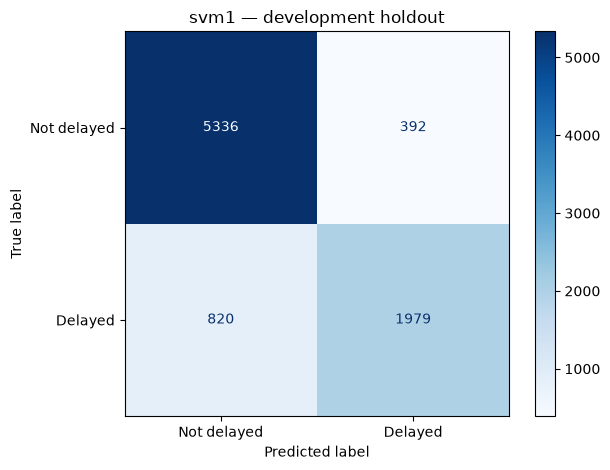

In [20]:
start=time.perf_counter()
features=FocusedCatBoostFeatures(profile,reference=True,local_trend=False)
train_frame=features.fit_transform(X_train,y_train)
holdout_frame=features.transform(X_holdout)
stress_frame=features.transform(mask_to_profile(X_holdout,profile,9871))
model=TunedFlightEstimator(selected_spec).fit(train_frame,y_train)
holdout_scores=model.scores(holdout_frame)
holdout_predictions=(holdout_scores>=selected_threshold).astype(int)
metrics=dict(accuracy=float(accuracy_score(y_holdout,holdout_predictions)),
    weighted_f1=float(f1_score(y_holdout,holdout_predictions,average='weighted')),
    macro_f1=float(f1_score(y_holdout,holdout_predictions,average='macro')),
    delay_f1=float(f1_score(y_holdout,holdout_predictions)),
    roc_auc=float(roc_auc_score(y_holdout,holdout_scores)))
stress_predictions=(model.scores(stress_frame)>=selected_threshold).astype(int)
stress_metrics=dict(accuracy=float(accuracy_score(y_holdout,stress_predictions)),
    weighted_f1=float(f1_score(y_holdout,stress_predictions,average='weighted')))
print('HOLDOUT RESULTS:',{k:round(v,4) for k,v in metrics.items()})
print('Missing-value stress:',{k:round(v,4) for k,v in stress_metrics.items()})
print(classification_report(y_holdout,holdout_predictions,target_names=['Not delayed (0)','Delayed (1)'],digits=4))
print('Evaluation seconds:',round(time.perf_counter()-start,1))
ConfusionMatrixDisplay.from_predictions(y_holdout,holdout_predictions,display_labels=['Not delayed','Delayed'],cmap='Blues')
plt.title(OUTPUT_STEM+' — development holdout');plt.tight_layout();plt.show()

## 6. Source-order sensitivity check
This diagnostic shuffles flights within each day of the holdout, recomputes its context and evaluates the same frozen model. It does not select settings. A substantial drop demonstrates reliance on the original ordering and must be disclosed when interpreting the result.

In [21]:
ordered=ordered_dates(X_holdout).sort_index()
parts=[];rng=np.random.default_rng(9871)
for _,g in ordered.groupby('DATE',sort=False):
    parts.extend(rng.permutation(g.index).tolist())
shuffled=X_holdout.loc[parts].reset_index(drop=True)
shuffled_y=y_holdout.loc[parts].to_numpy()
shuffled_frame=features.transform(shuffled)
order_control_accuracy=float(accuracy_score(shuffled_y,model.scores(shuffled_frame)>=selected_threshold))
print('Original-order holdout accuracy:',round(metrics['accuracy'],4))
print('Shuffled-within-day control accuracy:',round(order_control_accuracy,4))

Original-order holdout accuracy: 0.8579
Shuffled-within-day control accuracy: 0.5406


## 7. Refit all labelled rows and generate `svm1.csv`
The final model uses the settings selected inside the training 80%. Predictions are generated from the original unknown row order. IDs come directly from the Kaggle sample. The exported columns are exactly `row ID` and `Predicted_Arrival_Delay`.

The CSV is saved beside the Flight input file, with no extra output folder. If VS Code's Explorer has not refreshed, click its Refresh icon. Submit this CSV to Kaggle and record the actual score separately. Re-running the notebook replaces the same `svm1.csv`.

In [22]:
print('Refitting selected model on all',len(X),'labelled rows...',flush=True)
final_features=FocusedCatBoostFeatures(profile,reference=True,local_trend=False)
final_training_frame=final_features.fit_transform(X,y)
final_model=TunedFlightEstimator(selected_spec).fit(final_training_frame,y)
unknown_frame=final_features.transform(unknown)
unknown_predictions=(final_model.scores(unknown_frame)>=selected_threshold).astype(np.int8)
assert len(unknown_predictions)==len(unknown)==len(sample)
submission=pd.DataFrame({'row ID':sample['row ID'].to_numpy(),
                         'Predicted_Arrival_Delay':unknown_predictions})
assert list(submission.columns)==['row ID','Predicted_Arrival_Delay']
assert submission['row ID'].equals(sample['row ID'])
assert submission['Predicted_Arrival_Delay'].isin([0,1]).all()
OUTPUT_FILE=TRAIN_FILE.parent/(OUTPUT_STEM+'.csv')
submission.to_csv(OUTPUT_FILE,index=False)
saved=pd.read_csv(OUTPUT_FILE,dtype={'row ID':str})
assert saved.equals(submission.astype({'Predicted_Arrival_Delay':'int64'}))
print('CSV GENERATED:',OUTPUT_FILE.resolve())
print('Rows:',len(saved),'| Columns:',list(saved.columns))
print('Predicted delay proportion:',round(float(saved.Predicted_Arrival_Delay.mean()),4))
print('SHA256:',hashlib.sha256(OUTPUT_FILE.read_bytes()).hexdigest())
display(FileLink(str(OUTPUT_FILE)))

Refitting selected model on all 42634 labelled rows...


c:\Users\user\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


CSV GENERATED: svm1.csv
Rows: 21318 | Columns: ['row ID', 'Predicted_Arrival_Delay']
Predicted delay proportion: 0.2847
SHA256: 51d482c28469e5eec13ed516e4d5552861a53958725692c97d57874b882128a1


svm1.csv

## Report notes and references
Report the selected parameters, tuning comparison, development-holdout accuracy and weighted F1, missingness stress result, and the actual Kaggle score after submission. Explain the row-order assumption, retrospective information and repeated use of the development holdout. Do not describe local validation as a measured Kaggle result.

Official implementation references: [scikit-learn classifiers and preprocessing](https://scikit-learn.org/stable/supervised_learning.html), [CatBoost parameter tuning](https://catboost.ai/docs/en/concepts/parameter-tuning), [LightGBM parameters](https://lightgbm.readthedocs.io/en/stable/Parameters.html).